# 04 – Modelling

**Project:** Energy-Aware Early Fault Detection in Semiconductor Wafer Fabrication (UCI SECOM)

Four classifiers, each trained with two ways of handling the ~14 : 1 class imbalance:

| Model | Imbalance option A: class weights | Imbalance option B: SMOTE |
|---|---|---|
| Logistic regression (L1 or L2) – baseline | `class_weight='balanced'` | SMOTE, no class weights |
| SVM (RBF kernel) | `class_weight='balanced'` | SMOTE, no class weights |
| Random forest | `class_weight='balanced'` | SMOTE, no class weights |
| XGBoost | `scale_pos_weight = n_pass / n_fail` (train set) | SMOTE, `scale_pos_weight = 1` |

Each of the 8 combinations is tuned with `RandomizedSearchCV` (40 candidates, `StratifiedKFold(5)`, shuffled
with `random_state=42`), optimising **PR-AUC** (`average_precision`).

### What runs inside each CV fold

Every candidate is one `imblearn` pipeline, refitted from scratch in every fold:

```
preprocessing (from 02) → ANOVA top-20 selection (from 03) → [SMOTE] → classifier
```

- **Preprocessing and feature selection are refitted inside each fold**, using the exact settings chosen in
  02 and 03. If we instead used the pipeline and feature list fitted on the *whole* training set, the
  validation folds would already have influenced the medians, scalers and – most importantly – which 20
  features were picked, which makes CV scores optimistic. After the final refit on the full training set,
  the selected features are exactly the 20 from notebook 03 (checked below).
- **SMOTE runs on the training part of each fold only.** The `imblearn` pipeline applies samplers during
  `fit` and skips them during `predict`, so validation folds always contain only real wafers.
- The test set (latest 20% of wafers) is **not used here**. It is reserved for 05_Evaluation.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so `src` works from notebooks/
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import shutil
import tempfile
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from joblib import Memory
from scipy.stats import loguniform, randint, uniform

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, precision_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.svm import SVC
from xgboost import XGBClassifier

from src.config import RANDOM_STATE, MODELS_DIR, OUTPUTS_DIR
from src.data_loader import load_secom, split_xy
from src.metrics import cost_scorer, DEFAULT_COST_FN, DEFAULT_COST_FP
from src.preprocessing import time_train_test_split, preprocessing_steps
from src.plotting import apply_style, save_fig, CATEGORICAL, REF_LINE_COLOR, TEXT_SECONDARY, SURFACE

np.random.seed(RANDOM_STATE)
apply_style()

df = load_secom()
train_df, test_df = time_train_test_split(df, test_size=0.2)
X_train, y_train = split_xy(train_df)      # raw sensors: the pipeline does all preprocessing

n_pass, n_fail = int((y_train == 0).sum()), int((y_train == 1).sum())
SCALE_POS_WEIGHT = n_pass / n_fail
print(f'Training wafers: {len(y_train)} ({n_pass} pass / {n_fail} fail)')
print(f'XGBoost scale_pos_weight = {n_pass} / {n_fail} = {SCALE_POS_WEIGHT:.2f}')

fs = json.loads((MODELS_DIR / 'selected_features.json').read_text())
print(f"Feature selection from 03: {fs['method']}, k = {fs['k']}")

Training wafers: 1254 (1167 pass / 87 fail)
XGBoost scale_pos_weight = 1167 / 87 = 13.41
Feature selection from 03: ANOVA F-test, k = 20


## 1. Pipelines, search spaces and scoring

In [2]:
def make_selector(method, k):
    """Same selector notebook 03 chose (re-fitted inside every CV fold)."""
    if method == 'ANOVA F-test':
        return SelectKBest(f_classif, k=k)
    raise NotImplementedError(f'Add the selector for {method!r} (see 03_Feature_Selection).')

# Preprocessing (YJ etc.) is the slow part and is identical for every candidate within a fold, so cache it.
CACHE_DIR = tempfile.mkdtemp(prefix='secom_cache_')
memory = Memory(CACHE_DIR, verbose=0)

def make_pipeline(clf, use_smote):
    steps = preprocessing_steps() + [('select', make_selector(fs['method'], fs['k']))]
    if use_smote:
        steps.append(('smote', SMOTE(random_state=RANDOM_STATE)))
    steps.append(('clf', clf))
    return Pipeline(steps, memory=memory)

# scikit-learn >= 1.8 sets L1 vs L2 with l1_ratio (1 = L1, 0 = L2); older versions use penalty=
_SK_NEW = tuple(int(x) for x in sklearn.__version__.split('.')[:2]) >= (1, 8)
LR_PENALTY = {'clf__l1_ratio': [0, 1]} if _SK_NEW else {'clf__penalty': ['l1', 'l2']}

In [3]:
def model_specs(use_smote):
    """(classifier, parameter distributions) for each model. Class weights are used only without SMOTE."""
    cw = None if use_smote else 'balanced'
    return {
        'Logistic regression': (
            LogisticRegression(solver='liblinear', class_weight=cw, max_iter=5000, random_state=RANDOM_STATE),
            {'clf__C': loguniform(1e-3, 1e2), **LR_PENALTY}),
        'SVM (RBF)': (
            SVC(kernel='rbf', class_weight=cw, random_state=RANDOM_STATE),   # scored via decision_function
            {'clf__C': loguniform(1e-2, 1e2), 'clf__gamma': loguniform(1e-4, 1e0)}),
        'Random forest': (
            RandomForestClassifier(class_weight=cw, n_jobs=1, random_state=RANDOM_STATE),
            {'clf__n_estimators': randint(200, 601), 'clf__max_depth': [None, 4, 6, 8, 12, 16],
             'clf__min_samples_leaf': randint(1, 11), 'clf__max_features': ['sqrt', 'log2', 0.3, 0.5]}),
        'XGBoost': (
            XGBClassifier(scale_pos_weight=1.0 if use_smote else SCALE_POS_WEIGHT, tree_method='hist',
                          eval_metric='aucpr', n_jobs=-1, random_state=RANDOM_STATE),
            {'clf__n_estimators': randint(100, 601), 'clf__max_depth': randint(2, 7),
             'clf__learning_rate': loguniform(0.01, 0.3), 'clf__subsample': uniform(0.6, 0.4),
             'clf__colsample_bytree': uniform(0.5, 0.5), 'clf__min_child_weight': randint(1, 11),
             'clf__reg_lambda': loguniform(0.1, 10)}),
    }

SMOTE_PARAMS = {'smote__k_neighbors': [3, 5, 7]}

# XGBoost's native library can crash ("access violation") inside joblib worker processes on Windows,
# so its search runs in one process and XGBoost uses its own threads instead. Results are unaffected.
SEARCH_N_JOBS = {'XGBoost': 1}

N_ITER = 40
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'pr_auc': 'average_precision',            # main metric (refit on this)
    'roc_auc': 'roc_auc',
    'recall': 'recall',
    'precision': make_scorer(precision_score, zero_division=0),
    'f1': 'f1',
    'neg_cost': cost_scorer(),               # energy-aware cost at the default 0.5 threshold (negated)
}
print(f'{N_ITER} candidates x 5 folds per search, 8 searches')
print(f'Energy cost = {DEFAULT_COST_FN:g} x missed faults + {DEFAULT_COST_FP:g} x false alarms (src/metrics.py)')

40 candidates x 5 folds per search, 8 searches
Energy cost = 10 x missed faults + 1 x false alarms (src/metrics.py)


## 2. Run the 8 searches

All searches use the same 5 folds, so every model and imbalance option is compared on identical data splits.
Recall, precision, F1 and cost are measured at the default 0.5 decision threshold; the threshold itself is
tuned for minimum cost in 05_Evaluation.

In [4]:
searches = {}
t_all = time.time()
for use_smote in (False, True):
    imb = 'SMOTE' if use_smote else 'Class weights'
    for name, (clf, params) in model_specs(use_smote).items():
        dist = {**params, **(SMOTE_PARAMS if use_smote else {})}
        search = RandomizedSearchCV(
            make_pipeline(clf, use_smote), dist, n_iter=N_ITER, cv=cv, scoring=scoring, refit='pr_auc',
            n_jobs=SEARCH_N_JOBS.get(name, -1), random_state=RANDOM_STATE, return_train_score=True,
            error_score='raise')
        t0 = time.time()
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', category=UserWarning)   # e.g. joblib memory messages
            search.fit(X_train, y_train)
        searches[(name, imb)] = search
        print(f'{name:<20} {imb:<14} best CV PR-AUC {search.best_score_:.3f}   ({time.time() - t0:.0f} s)')
print(f'\nAll searches done in {(time.time() - t_all) / 60:.1f} min')

Logistic regression  Class weights  best CV PR-AUC 0.208   (49 s)


SVM (RBF)            Class weights  best CV PR-AUC 0.201   (21 s)


Random forest        Class weights  best CV PR-AUC 0.243   (51 s)


XGBoost              Class weights  best CV PR-AUC 0.252   (195 s)


Logistic regression  SMOTE          best CV PR-AUC 0.197   (18 s)


SVM (RBF)            SMOTE          best CV PR-AUC 0.211   (26 s)


Random forest        SMOTE          best CV PR-AUC 0.229   (81 s)


XGBoost              SMOTE          best CV PR-AUC 0.264   (198 s)

All searches done in 10.6 min


## 3. CV results table

In [5]:
rows, all_candidates = [], []
for (name, imb), s in searches.items():
    r = pd.DataFrame(s.cv_results_)
    i = s.best_index_
    rows.append({
        'model': name, 'imbalance': imb,
        'pr_auc_mean': r.loc[i, 'mean_test_pr_auc'], 'pr_auc_std': r.loc[i, 'std_test_pr_auc'],
        'roc_auc_mean': r.loc[i, 'mean_test_roc_auc'], 'roc_auc_std': r.loc[i, 'std_test_roc_auc'],
        'recall_mean': r.loc[i, 'mean_test_recall'], 'precision_mean': r.loc[i, 'mean_test_precision'],
        'f1_mean': r.loc[i, 'mean_test_f1'],
        'cost_mean': -r.loc[i, 'mean_test_neg_cost'], 'cost_std': r.loc[i, 'std_test_neg_cost'],
        'train_pr_auc_mean': r.loc[i, 'mean_train_pr_auc'],
        'fit_time_s': r.loc[i, 'mean_fit_time'],
        'best_params': json.dumps({k.replace('clf__', '').replace('smote__', 'smote_'): (v.item() if hasattr(v, 'item') else v)
                                   for k, v in s.best_params_.items()}),
    })
    r.insert(0, 'imbalance', imb); r.insert(0, 'model', name)
    all_candidates.append(r)

results = pd.DataFrame(rows).sort_values('pr_auc_mean', ascending=False).reset_index(drop=True)
candidates = pd.concat(all_candidates, ignore_index=True)

# Reference: cost of never flagging a fault, per validation fold (average)
fails_per_fold = n_fail / cv.get_n_splits()
cost_flag_nothing = DEFAULT_COST_FN * fails_per_fold

show = results[['model', 'imbalance', 'pr_auc_mean', 'pr_auc_std', 'roc_auc_mean', 'recall_mean',
                'precision_mean', 'f1_mean', 'cost_mean', 'train_pr_auc_mean']].round(3)
print(show.to_string(index=False))
print(f'\nReferences: random-model PR-AUC = fail rate = {y_train.mean():.3f}; '
      f'cost of flagging nothing = {cost_flag_nothing:.1f} per validation fold')

              model     imbalance  pr_auc_mean  pr_auc_std  roc_auc_mean  recall_mean  precision_mean  f1_mean  cost_mean  train_pr_auc_mean
            XGBoost         SMOTE        0.264       0.091         0.719        0.300           0.296    0.294      136.0              1.000
            XGBoost Class weights        0.252       0.070         0.723        0.239           0.310    0.264      142.0              1.000
      Random forest Class weights        0.243       0.100         0.749        0.275           0.241    0.253      142.6              1.000
      Random forest         SMOTE        0.229       0.126         0.736        0.218           0.249    0.231      148.0              0.996
          SVM (RBF)         SMOTE        0.211       0.113         0.663        0.266           0.195    0.222      149.4              0.836
Logistic regression Class weights        0.208       0.072         0.722        0.575           0.141    0.226      136.4              0.278
          SVM

In [6]:
results_path = OUTPUTS_DIR / '04_cv_results.csv'
results.round(4).to_csv(results_path, index=False)

cand_cols = ['model', 'imbalance', 'params', 'rank_test_pr_auc'] + \
            [c for c in candidates.columns if c.startswith(('mean_test_', 'std_test_', 'mean_train_pr_auc', 'mean_fit_time'))]
candidates[cand_cols].assign(params=candidates['params'].astype(str)) \
    .sort_values(['model', 'imbalance', 'rank_test_pr_auc']).round(4) \
    .to_csv(OUTPUTS_DIR / '04_cv_results_all_candidates.csv', index=False)
print('Saved', results_path.relative_to(ROOT), 'and outputs/04_cv_results_all_candidates.csv')

Saved outputs\04_cv_results.csv and outputs/04_cv_results_all_candidates.csv


## 4. Compare models and imbalance options

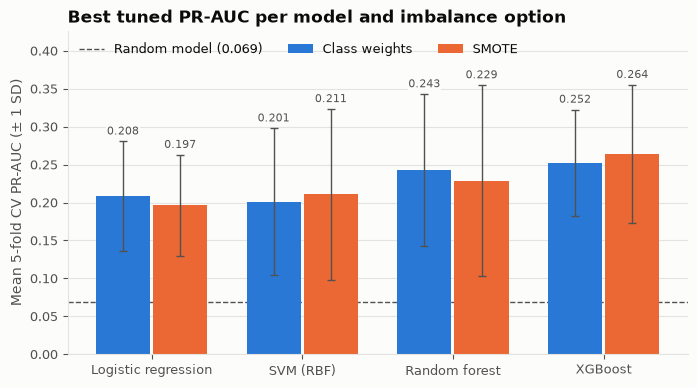

In [7]:
MODELS = ['Logistic regression', 'SVM (RBF)', 'Random forest', 'XGBoost']
IMB = ['Class weights', 'SMOTE']
IMB_COLORS = {'Class weights': CATEGORICAL[0], 'SMOTE': CATEGORICAL[1]}
res_idx = results.set_index(['model', 'imbalance'])

def grouped_bars(ax, mean_col, std_col, fmt, ref=None, ref_label=None):
    x = np.arange(len(MODELS)); w = 0.36
    for j, imb in enumerate(IMB):
        means = [res_idx.loc[(m, imb), mean_col] for m in MODELS]
        stds = [res_idx.loc[(m, imb), std_col] for m in MODELS]
        pos = x + (j - 0.5) * (w + 0.02)
        ax.bar(pos, means, width=w, color=IMB_COLORS[imb], label=imb, zorder=2)
        ax.errorbar(pos, means, yerr=stds, fmt='none', ecolor=REF_LINE_COLOR, elinewidth=1, capsize=3, zorder=3)
        for p, v, s in zip(pos, means, stds):
            ax.annotate(fmt.format(v), (p, v + s), xytext=(0, 3), textcoords='offset points',
                        ha='center', va='bottom', fontsize=8, color=TEXT_SECONDARY, zorder=4,
                        bbox=dict(facecolor=SURFACE, edgecolor='none', pad=0.5))
    if ref is not None:
        ax.axhline(ref, color=REF_LINE_COLOR, linestyle='--', linewidth=1, label=ref_label, zorder=1)
    ax.set_xticks(x, MODELS)
    ax.grid(axis='x', visible=False)

fig, ax = plt.subplots(figsize=(8, 4.2))
grouped_bars(ax, 'pr_auc_mean', 'pr_auc_std', '{:.3f}', ref=y_train.mean(), ref_label=f'Random model ({y_train.mean():.3f})')
ax.set_ylim(0, (results['pr_auc_mean'] + results['pr_auc_std']).max() * 1.2)
ax.set_ylabel('Mean 5-fold CV PR-AUC (± 1 SD)')
ax.set_title('Best tuned PR-AUC per model and imbalance option')
ax.legend(loc='upper left', ncol=3)
save_fig(fig, '04_cv_pr_auc_by_model')
plt.show()

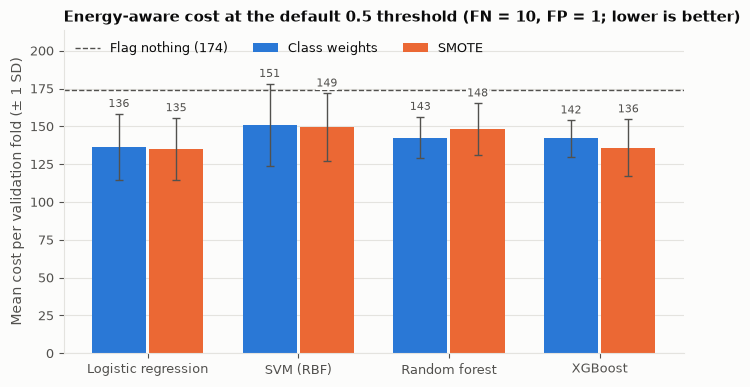

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
grouped_bars(ax, 'cost_mean', 'cost_std', '{:.0f}', ref=cost_flag_nothing,
             ref_label=f'Flag nothing ({cost_flag_nothing:.0f})')
ax.set_ylim(0, max((results['cost_mean'] + results['cost_std']).max(), cost_flag_nothing) * 1.2)
ax.set_ylabel('Mean cost per validation fold (± 1 SD)')
ax.set_title(f'Energy-aware cost at the default 0.5 threshold (FN = {DEFAULT_COST_FN:g}, FP = {DEFAULT_COST_FP:g}; lower is better)',
             fontsize=11)
ax.legend(loc='upper left', ncol=3)
save_fig(fig, '04_cv_cost_by_model')
plt.show()

In [9]:
# Over-fitting check: training-fold vs validation-fold PR-AUC for each best candidate
gap = results[['model', 'imbalance', 'train_pr_auc_mean', 'pr_auc_mean']].copy()
gap['gap'] = gap['train_pr_auc_mean'] - gap['pr_auc_mean']
print(gap.round(3).to_string(index=False))

              model     imbalance  train_pr_auc_mean  pr_auc_mean   gap
            XGBoost         SMOTE              1.000        0.264 0.735
            XGBoost Class weights              1.000        0.252 0.748
      Random forest Class weights              1.000        0.243 0.757
      Random forest         SMOTE              0.996        0.229 0.767
          SVM (RBF)         SMOTE              0.836        0.211 0.625
Logistic regression Class weights              0.278        0.208 0.069
          SVM (RBF) Class weights              0.925        0.201 0.723
Logistic regression         SMOTE              0.286        0.197 0.090


**Reading the results**

- **Tree ensembles rank highest.** XGBoost (0.264 with SMOTE, 0.252 with class weights) and random forest
  (0.243 with class weights) lead on PR-AUC, about 3.5× a random model (0.069). Logistic regression and SVM
  sit around 0.20–0.21.
- **The differences are small compared with the noise.** Fold-to-fold SDs are 0.07–0.13, so the top three
  configurations overlap heavily and no model is a clear winner yet. The time-ordered test set in 05 is the
  real check.
- **SMOTE vs class weights: no consistent winner.** SMOTE helps XGBoost (+0.012) and SVM (+0.010) but hurts
  random forest (−0.014) and logistic regression (−0.011) – all well inside the noise. Class weights are
  simpler and cheaper, so SMOTE is not clearly worth its extra complexity on this data.
- **Tree models over-fit the training folds.** Their training PR-AUC is about 1.0 against about 0.25 on
  validation; logistic regression's gap is only ~0.07. With just ~70 fails per training fold, the trees can
  memorise them. Stronger regularisation (shallower trees, larger `min_samples_leaf`) is worth trying if the
  test results disappoint.
- **At the default 0.5 threshold, every model already beats "flag nothing" on energy cost** (135–151 vs 174
  per fold), but only modestly. Logistic regression has the lowest cost despite a lower PR-AUC because
  class weighting pushes it to flag more wafers (recall 0.58–0.67), and with FN = 10 × FP missing a fault is
  what costs most. This shows the ranking by PR-AUC is not the ranking by cost at a fixed threshold – the
  threshold must be tuned for cost, which 05_Evaluation does.

## 5. Save the best model per algorithm

For each algorithm we keep the imbalance option with the higher CV PR-AUC. `RandomizedSearchCV` has already
refitted that pipeline on the **full training set**, so each saved file is a complete model:
**raw 590 sensors in → fail probability out** (preprocessing, feature selection and classifier included;
SMOTE is skipped automatically at prediction time).

In [10]:
FILE_NAMES = {'Logistic regression': 'logistic_regression', 'SVM (RBF)': 'svm_rbf',
              'Random forest': 'random_forest', 'XGBoost': 'xgboost'}
best_per_model = results.loc[results.groupby('model')['pr_auc_mean'].idxmax()].sort_values('pr_auc_mean', ascending=False)

manifest = {'random_state': RANDOM_STATE, 'cv': 'StratifiedKFold(5, shuffle=True, random_state=42) on the training set',
            'scoring': 'average_precision (PR-AUC)', 'n_iter': N_ITER, 'models': {}}
for _, row in best_per_model.iterrows():
    est = searches[(row['model'], row['imbalance'])].best_estimator_
    est.memory = None                                   # drop the temporary cache reference before saving
    path = MODELS_DIR / f"{FILE_NAMES[row['model']]}.joblib"
    joblib.dump(est, path)

    # The final refit must use exactly the 20 features chosen in notebook 03
    kept = np.array(est.named_steps['drop_correlated'].keep_)
    used = sorted(kept[est.named_steps['select'].get_support()])
    assert used == sorted(fs['selected_features']), 'feature mismatch with notebook 03'

    manifest['models'][row['model']] = {
        'file': f'outputs/models/{path.name}', 'imbalance': row['imbalance'],
        'cv_pr_auc_mean': round(row['pr_auc_mean'], 4), 'cv_pr_auc_std': round(row['pr_auc_std'], 4),
        'cv_roc_auc_mean': round(row['roc_auc_mean'], 4), 'best_params': json.loads(row['best_params'])}
    print(f"Saved {path.relative_to(ROOT)}  ({row['imbalance']}, CV PR-AUC {row['pr_auc_mean']:.3f}, "
          f"{path.stat().st_size / 1024:.0f} KB)")

overall = best_per_model.iloc[0]
manifest['best_overall'] = overall['model']
(MODELS_DIR / 'best_models.json').write_text(json.dumps(manifest, indent=2))
print('Saved outputs/models/best_models.json')
print('All saved models use exactly the 20 features from notebook 03.')

Saved outputs\models\xgboost.joblib  (SMOTE, CV PR-AUC 0.264, 249 KB)


Saved outputs\models\random_forest.joblib  (Class weights, CV PR-AUC 0.243, 2654 KB)
Saved outputs\models\svm_rbf.joblib  (SMOTE, CV PR-AUC 0.211, 239 KB)
Saved outputs\models\logistic_regression.joblib  (Class weights, CV PR-AUC 0.208, 90 KB)
Saved outputs/models/best_models.json
All saved models use exactly the 20 features from notebook 03.


In [11]:
# Sanity check: reload one model and predict on raw training rows
for name in best_per_model['model']:
    m = joblib.load(MODELS_DIR / f'{FILE_NAMES[name]}.joblib')
    if hasattr(m, 'predict_proba'):
        s, kind = m.predict_proba(X_train.iloc[:5])[:, 1], 'P(fail)'
    else:   # SVC without probability=True: use the decision score (05 can calibrate it)
        s, kind = m.decision_function(X_train.iloc[:5]), 'decision score'
    print(f'Reloaded {name:<20} {kind} for 5 training wafers: {np.round(s, 3)}')

shutil.rmtree(CACHE_DIR, ignore_errors=True)     # remove the temporary preprocessing cache

Reloaded XGBoost              P(fail) for 5 training wafers: [0.003 0.003 0.981 0.016 0.001]


Reloaded Random forest        P(fail) for 5 training wafers: [0.376 0.246 0.941 0.313 0.168]
Reloaded SVM (RBF)            decision score for 5 training wafers: [-0.755 -2.098  1.    -0.857 -1.   ]
Reloaded Logistic regression  P(fail) for 5 training wafers: [0.657 0.716 0.926 0.721 0.167]


### Summary

In [12]:
print(f'Best overall by CV PR-AUC: {overall["model"]} with {overall["imbalance"]} '
      f'(PR-AUC {overall["pr_auc_mean"]:.3f} ± {overall["pr_auc_std"]:.3f}, ROC-AUC {overall["roc_auc_mean"]:.3f})\n')
w = max(len(m) for m in MODELS)
for _, r in best_per_model.iterrows():
    print(f"{r['model']:<{w}}  {r['imbalance']:<14} PR-AUC {r['pr_auc_mean']:.3f} ± {r['pr_auc_std']:.3f}   "
          f"recall {r['recall_mean']:.2f}   cost {r['cost_mean']:.1f}")

Best overall by CV PR-AUC: XGBoost with SMOTE (PR-AUC 0.264 ± 0.091, ROC-AUC 0.719)

XGBoost              SMOTE          PR-AUC 0.264 ± 0.091   recall 0.30   cost 136.0
Random forest        Class weights  PR-AUC 0.243 ± 0.100   recall 0.28   cost 142.6
SVM (RBF)            SMOTE          PR-AUC 0.211 ± 0.113   recall 0.27   cost 149.4
Logistic regression  Class weights  PR-AUC 0.208 ± 0.072   recall 0.58   cost 136.4


**Next (05_Evaluation):** load the four saved models, tune each one's decision threshold for minimum energy cost
on out-of-fold training predictions, then evaluate once on the untouched time-ordered test set.